<style>
body, .rendered_html {
  font-family: 'Segoe UI', Arial, sans-serif !important;
  font-size: 14px;
  line-height: 1.6;
  color: #2c3e50;
}
h1, h2, h3 {
  color: #1a5276;
  font-weight: bold;
}
code {
  font-family: 'Fira Code', Consolas, monospace !important;
}
</style>

# **TP N°4 — Le Transformer et ses applications**

## Première partie : les étapes 1 à 6

Cette première partie compare plusieurs familles de modèles sur des données simples.

1. Nous construisons une série temporelle `y = sin(x)` et la transformons en fenêtres glissantes.
2. Nous entraînons un RNN simple pour prédire la valeur suivante.
3. Nous répétons l’expérience avec un LSTM.
4. Nous construisons un petit Transformer avec un encodeur et deux têtes d’attention.
5. Nous utilisons GPT-2 pré-entraîné pour poursuivre un texte.
6. Nous utilisons BERT pré-entraîné pour proposer un mot à la place d’un masque.

Les étapes sur la série temporelle sont adaptées à une exécution sur CPU. Les étapes GPT-2 et BERT exigent un téléchargement des modèles pré-entraînés.

**Installation des dépendances :** `pip install torch transformers matplotlib`

In [1]:
import math
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Jeu de données : `y = sin(x)`

La série est générée sur l’intervalle allant de 0 à 20. Chaque exemple contient dix valeurs consécutives, et l’étiquette correspond à la valeur immédiatement suivante.

Ce découpage permet de transformer une suite continue en exemples d’apprentissage supervisé. La séparation conserve l’ordre chronologique : les premières fenêtres servent à l’entraînement et les dernières à l’évaluation.

X : (190, 10, 1) | Y : (190, 1)
train : (150, 10, 1) | test : (40, 10, 1)


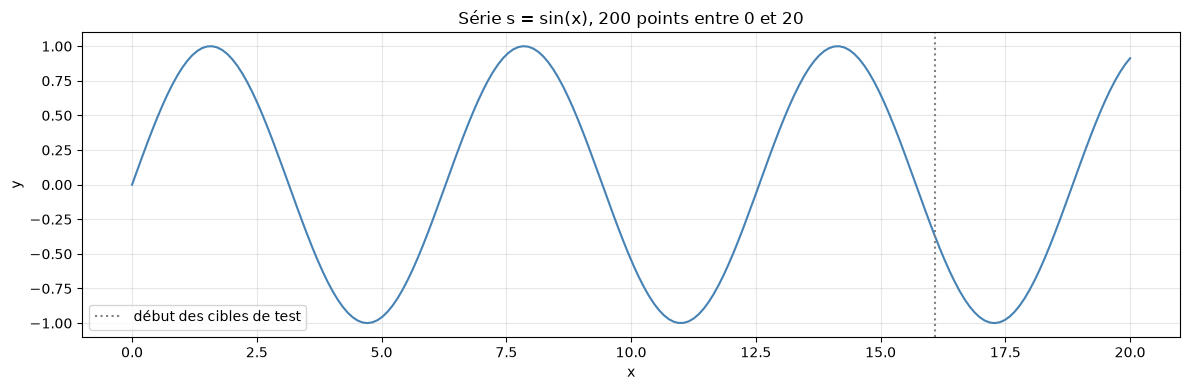

In [2]:
NB_POINTS = 200
LONGUEUR_SEQ = 10
NB_TRAIN = 150          # 150 fenêtres pour l’entraînement et 40 pour le test
BATCH_SIZE = 16

x_axe = torch.linspace(0, 20, NB_POINTS)
serie = torch.sin(x_axe)                       # Série contenant 200 points


def fenetres_glissantes(serie, longueur):
    n = len(serie) - longueur
    X = torch.stack([serie[i:i + longueur] for i in range(n)])   # Fenêtres d’entrée de forme (190, 10)
    y = torch.stack([serie[i + longueur] for i in range(n)])     # Valeurs cibles de forme (190,)
    return X.unsqueeze(-1), y.unsqueeze(-1)    # Ajout de la dimension des caractéristiques


X, Y = fenetres_glissantes(serie, LONGUEUR_SEQ)
print("X :", tuple(X.shape), "| Y :", tuple(Y.shape))

# Vérifie que la troisième fenêtre contient s2 à s11 et vise s12
assert torch.equal(X[2, :, 0], serie[2:12]) and Y[2].item() == serie[12].item()

X_train, Y_train = X[:NB_TRAIN], Y[:NB_TRAIN]
X_test, Y_test = X[NB_TRAIN:], Y[NB_TRAIN:]
print("train :", tuple(X_train.shape), "| test :", tuple(X_test.shape))

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, Y_train),
                          batch_size=BATCH_SIZE, shuffle=True, generator=g)
test_loader = DataLoader(TensorDataset(X_test, Y_test),
                         batch_size=BATCH_SIZE, shuffle=False)

# La première cible du test est s160 ; x_axe[160] marque son début
plt.figure(figsize=(12, 4))
plt.plot(x_axe, serie, color="steelblue")
plt.axvline(x_axe[NB_TRAIN + LONGUEUR_SEQ], color="gray", linestyle=":", label="début des cibles de test")
plt.title("Série s = sin(x), 200 points entre 0 et 20")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Outils communs

Cette section rassemble les fonctions utilisées par les modèles RNN, LSTM et Transformer. Elles permettent d’entraîner les réseaux, de calculer les erreurs, d’afficher quelques prédictions et de comparer les résultats obtenus.

In [3]:
EPOCHS = 100
LR = 0.01
resultats = {}          # Résultats et prédictions associés à chaque modèle


def compter_parametres(modele):
    return sum(p.numel() for p in modele.parameters())


def entrainer(modele, loader, epochs=EPOCHS, lr=LR):
    modele.to(device)
    critere = nn.MSELoss()
    optimiseur = torch.optim.Adam(modele.parameters(), lr=lr)
    # Le taux d’apprentissage diminue afin de stabiliser les dernières mises à jour.
    planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=epochs)
    historique = []

    for epoch in range(epochs):
        modele.train()
        somme, n = 0.0, 0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            perte = critere(modele(xb), yb)

            optimiseur.zero_grad()
            perte.backward()
            optimiseur.step()

            somme += perte.item() * len(xb)
            n += len(xb)

        planning.step()
        historique.append(somme / n)
        if (epoch + 1) % 20 == 0:
            print(f"Epoch {epoch + 1:3d} | MSE train : {historique[-1]:.6f}")
    return historique


@torch.no_grad()
def evaluer(modele, loader):
    modele.eval()
    preds, reels = [], []
    for xb, yb in loader:
        preds.append(modele(xb.to(device)).cpu())
        reels.append(yb)
    preds, reels = torch.cat(preds), torch.cat(reels)
    mse = nn.functional.mse_loss(preds, reels).item()
    mae = (preds - reels).abs().mean().item()
    return preds.squeeze(1), reels.squeeze(1), mse, math.sqrt(mse), mae


@torch.no_grad()
def afficher_echantillons(nom, modele):
    # Les premières fenêtres d’entraînement correspondent à s10, s11 et s12.
    # Les premières fenêtres de test correspondent à s160, s161 et s162.
    idx = [0, 1, 2, NB_TRAIN, NB_TRAIN + 1, NB_TRAIN + 2]
    modele.eval()
    pred = modele(X[idx].to(device)).cpu().squeeze(1)
    print(f"\n{nom} : exemples")
    for i, p in zip(idx, pred):
        zone = "train" if i < NB_TRAIN else "test "
        print(f"  s{i + LONGUEUR_SEQ:<3d} ({zone}) réel = {Y[i].item():+.4f} | prédit = {p.item():+.4f}")


def tester(nom, modele, historique):
    preds, reels, mse, rmse, mae = evaluer(modele, test_loader)
    resultats[nom] = dict(preds=preds.numpy(), reels=reels.numpy(), mse=mse, rmse=rmse,
                          mae=mae, historique=historique, params=compter_parametres(modele))
    print(f"\n{nom} | test : MSE = {mse:.6f} | RMSE = {rmse:.4f} | MAE = {mae:.4f}")
    afficher_echantillons(nom, modele)


def tracer_predictions(nom, couleur="red"):
    r = resultats[nom]
    plt.figure(figsize=(12, 4.5))
    plt.plot(r["reels"], label="Valeurs réelles", color="blue", linewidth=2)
    plt.plot(r["preds"], label=f"Prédictions du {nom}", color=couleur, linestyle="--", linewidth=2)
    plt.title(f"{nom} : valeurs réelles et prédictions (test)")
    plt.xlabel("Indice de l'échantillon de test")
    plt.ylabel("Valeur")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 2. Modèle RNN

Le RNN traite la fenêtre une valeur à la fois et conserve un état caché résumant les éléments déjà observés. L’état correspondant à la dernière position est transmis à une couche linéaire afin de prédire la valeur suivante.

In [4]:
class SimpleRNN(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.rnn = nn.RNN(input_size=1, hidden_size=hidden_size, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)

    def forward(self, x):                      # Entrée de forme (B, 10, 1)
        etats, _ = self.rnn(x)                 # Sortie de forme (B, 10, 16)
        dernier = etats[:, -1, :]              # Dernier état caché de forme (B, 16)
        return self.sortie(dernier)            # Prédiction de forme (B, 1)


torch.manual_seed(SEED)
rnn = SimpleRNN()
print(rnn)
print("paramètres :", compter_parametres(rnn))
print("sortie sur un lot :", tuple(rnn(X_train[:4]).shape))   # Forme attendue : (4, 1)

SimpleRNN(
  (rnn): RNN(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 321
sortie sur un lot : (4, 1)


Epoch  20 | MSE train : 0.000219
Epoch  40 | MSE train : 0.000059
Epoch  60 | MSE train : 0.000010
Epoch  80 | MSE train : 0.000006
Epoch 100 | MSE train : 0.000005

RNN | test : MSE = 0.000006 | RMSE = 0.0025 | MAE = 0.0021

RNN : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8447
  s11  (train) réel = +0.8937 | prédit = +0.8941
  s12  (train) réel = +0.9342 | prédit = +0.9341
  s160 (test ) réel = -0.3639 | prédit = -0.3608
  s161 (test ) réel = -0.4555 | prédit = -0.4533
  s162 (test ) réel = -0.5425 | prédit = -0.5418


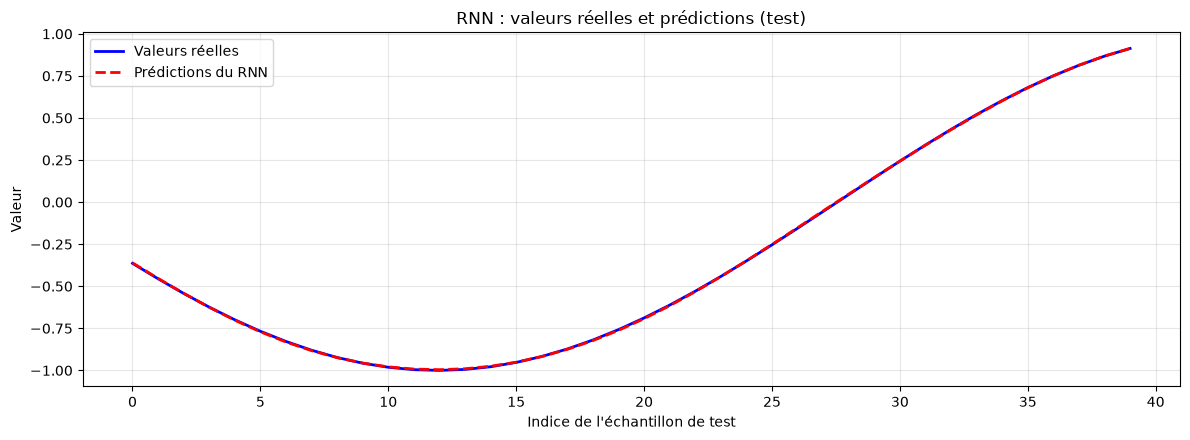

In [5]:
hist_rnn = entrainer(rnn, train_loader)
tester("RNN", rnn, hist_rnn)
tracer_predictions("RNN", "red")

## 3. Modèle LSTM

Le LSTM est une architecture récurrente dotée de portes qui régulent la mémoire à court et à long terme. Cette organisation lui permet de conserver plus facilement certaines informations utiles sur toute la séquence.

In [6]:
class SimpleLSTM(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.lstm = nn.LSTM(input_size=1, hidden_size=hidden_size, num_layers=1, batch_first=True)
        self.sortie = nn.Linear(hidden_size, 1)

    def forward(self, x):                      # Entrée de forme (B, 10, 1)
        etats, (h_n, c_n) = self.lstm(x)       # États de forme (B, 10, 16)
        dernier = etats[:, -1, :]              # Dernier état caché de forme (B, 16)
        return self.sortie(dernier)            # Prédiction de forme (B, 1)


torch.manual_seed(SEED)
lstm = SimpleLSTM()
print(lstm)
print("paramètres :", compter_parametres(lstm))
print("sortie sur un lot :", tuple(lstm(X_train[:4]).shape))

SimpleLSTM(
  (lstm): LSTM(1, 16, batch_first=True)
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 1233
sortie sur un lot : (4, 1)


Epoch  20 | MSE train : 0.000040
Epoch  40 | MSE train : 0.000026
Epoch  60 | MSE train : 0.000007
Epoch  80 | MSE train : 0.000004
Epoch 100 | MSE train : 0.000003

LSTM | test : MSE = 0.000003 | RMSE = 0.0017 | MAE = 0.0014

LSTM : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8458
  s11  (train) réel = +0.8937 | prédit = +0.8953
  s12  (train) réel = +0.9342 | prédit = +0.9351
  s160 (test ) réel = -0.3639 | prédit = -0.3630
  s161 (test ) réel = -0.4555 | prédit = -0.4559
  s162 (test ) réel = -0.5425 | prédit = -0.5441


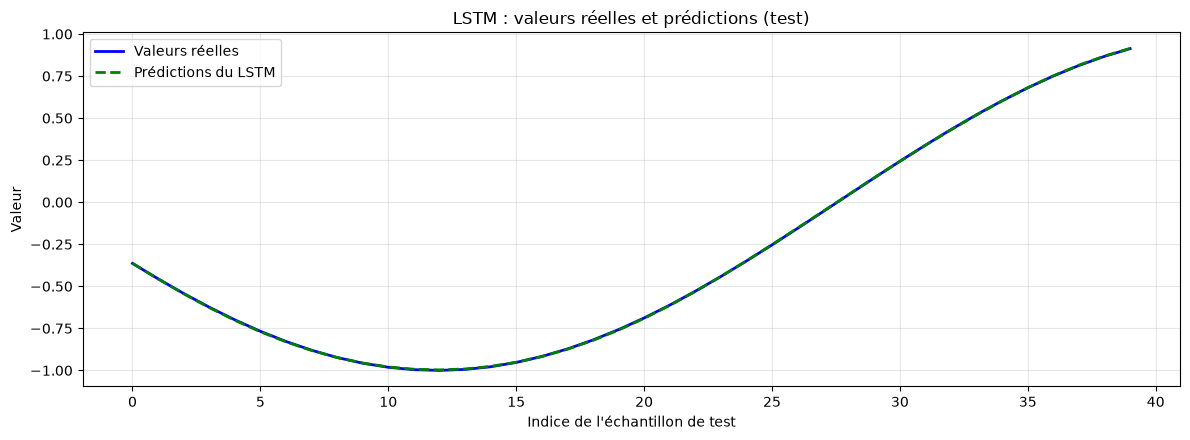

In [7]:
hist_lstm = entrainer(lstm, train_loader)
tester("LSTM", lstm, hist_lstm)
tracer_predictions("LSTM", "green")

## 4. Transformer avec encodeur

Ce modèle projette chaque valeur dans un espace de dimension 16, puis ajoute une représentation de sa position dans la fenêtre. Un bloc d’attention multi-têtes relie les différentes positions avant un réseau de sortie prédit la valeur suivante.

- Attention : 2 têtes ;
- Dimension du modèle : 16 ;
- Connexions résiduelles et normalisation ;
- Sortie calculée à partir de la dernière position.

In [8]:
class BlocEncodeur(nn.Module):
    def __init__(self, d_model=16, nb_tetes=2, d_ff=32, dropout=0.0):
        super().__init__()
        self.attention = nn.MultiheadAttention(d_model, nb_tetes, dropout=dropout, batch_first=True)
        self.norm1 = nn.LayerNorm(d_model)
        self.ff = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.ReLU(),
            nn.Linear(d_ff, d_model),
        )
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, retourner_poids=False):          # Entrée de forme (B, T, d_model)
        att, poids = self.attention(x, x, x, need_weights=retourner_poids)
        x = self.norm1(x + self.dropout(att))              # Connexion résiduelle puis normalisation
        x = self.norm2(x + self.dropout(self.ff(x)))       # Deuxième connexion résiduelle puis normalisation
        return x, poids                                    # Poids d’attention de forme (B, T, T)


class MiniTransformer(nn.Module):
    def __init__(self, longueur_max=10, d_model=16, nb_tetes=2, d_ff=32):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur_max, d_model)
        self.bloc = BlocEncodeur(d_model, nb_tetes, d_ff)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x, retourner_poids=False):          # Entrée de forme (B, 10, 1)
        T = x.size(1)
        h = self.projection(x)                             # Projection de forme (B, 10, 16)
        indices = torch.arange(T, device=x.device)         # Positions 0 à 9
        h = h + self.positions(indices).unsqueeze(0)       # Ajoute l’information de position
        h, poids = self.bloc(h, retourner_poids)           # Représentations de forme (B, 10, 16)
        y = self.sortie(h[:, -1, :])                       # Transforme la dernière position en une prédiction
        return (y, poids) if retourner_poids else y


torch.manual_seed(SEED)
transformer = MiniTransformer(longueur_max=LONGUEUR_SEQ)
print(transformer)
print("paramètres :", compter_parametres(transformer))

y_test_forme, poids_test = transformer(X_train[:4], retourner_poids=True)
print("sortie :", tuple(y_test_forme.shape), "| poids d'attention :", tuple(poids_test.shape))

MiniTransformer(
  (projection): Linear(in_features=1, out_features=16, bias=True)
  (positions): Embedding(10, 16)
  (bloc): BlocEncodeur(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQuantizableLinear(in_features=16, out_features=16, bias=True)
    )
    (norm1): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (ff): Sequential(
      (0): Linear(in_features=16, out_features=32, bias=True)
      (1): ReLU()
      (2): Linear(in_features=32, out_features=16, bias=True)
    )
    (norm2): LayerNorm((16,), eps=1e-05, elementwise_affine=True, bias=True)
    (dropout): Dropout(p=0.0, inplace=False)
  )
  (sortie): Linear(in_features=16, out_features=1, bias=True)
)
paramètres : 2433
sortie : (4, 1) | poids d'attention : (4, 10, 10)


Epoch  20 | MSE train : 0.000031
Epoch  40 | MSE train : 0.000014
Epoch  60 | MSE train : 0.000003
Epoch  80 | MSE train : 0.000002
Epoch 100 | MSE train : 0.000002

Transformer | test : MSE = 0.000002 | RMSE = 0.0015 | MAE = 0.0013

Transformer : exemples
  s10  (train) réel = +0.8442 | prédit = +0.8451
  s11  (train) réel = +0.8937 | prédit = +0.8946
  s12  (train) réel = +0.9342 | prédit = +0.9344
  s160 (test ) réel = -0.3639 | prédit = -0.3632
  s161 (test ) réel = -0.4555 | prédit = -0.4564
  s162 (test ) réel = -0.5425 | prédit = -0.5447


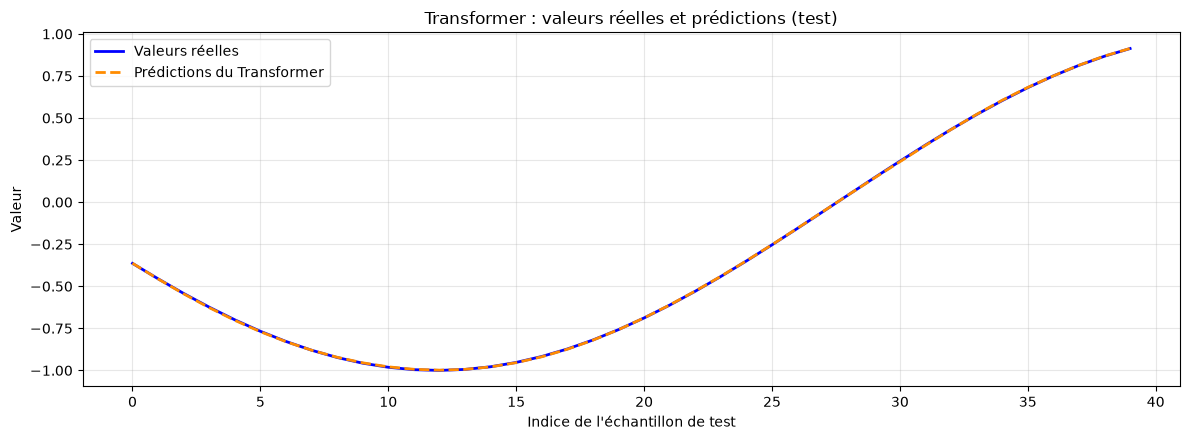

In [9]:
hist_transfo = entrainer(transformer, train_loader)
tester("Transformer", transformer, hist_transfo)
tracer_predictions("Transformer", "darkorange")

La visualisation suivante vérifie le comportement de l’attention. Les poids sont normalisés sur chaque ligne : la somme des poids associés à une position vaut donc 1.

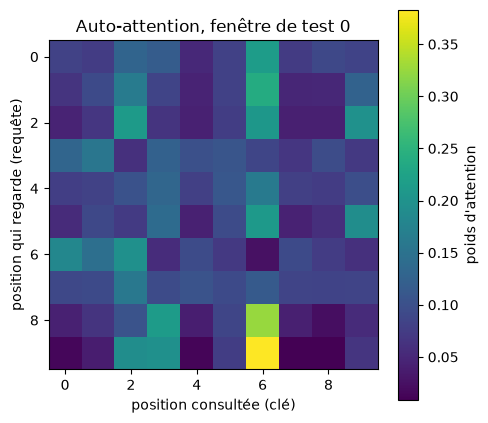

somme d'une ligne : 1.0000001192092896


In [10]:
transformer.eval()
with torch.no_grad():
    _, poids = transformer(X_test[:1].to(device), retourner_poids=True)   # (1, 10, 10)

plt.figure(figsize=(5, 4.5))
plt.imshow(poids[0].cpu().numpy(), cmap="viridis")
plt.colorbar(label="poids d'attention")
plt.title("Auto-attention, fenêtre de test 0")
plt.xlabel("position consultée (clé)")
plt.ylabel("position qui regarde (requête)")
plt.tight_layout()
plt.show()

print("somme d'une ligne :", poids[0, -1].sum().item())   # Vérifie que la somme des poids après normalisation softmax vaut 1

Modèle       paramètres     MSE test  RMSE test   MAE test
RNN                 321     0.000006     0.0025     0.0021
LSTM               1233     0.000003     0.0017     0.0014
Transformer        2433     0.000002     0.0015     0.0013

MSE de test la plus basse : Transformer


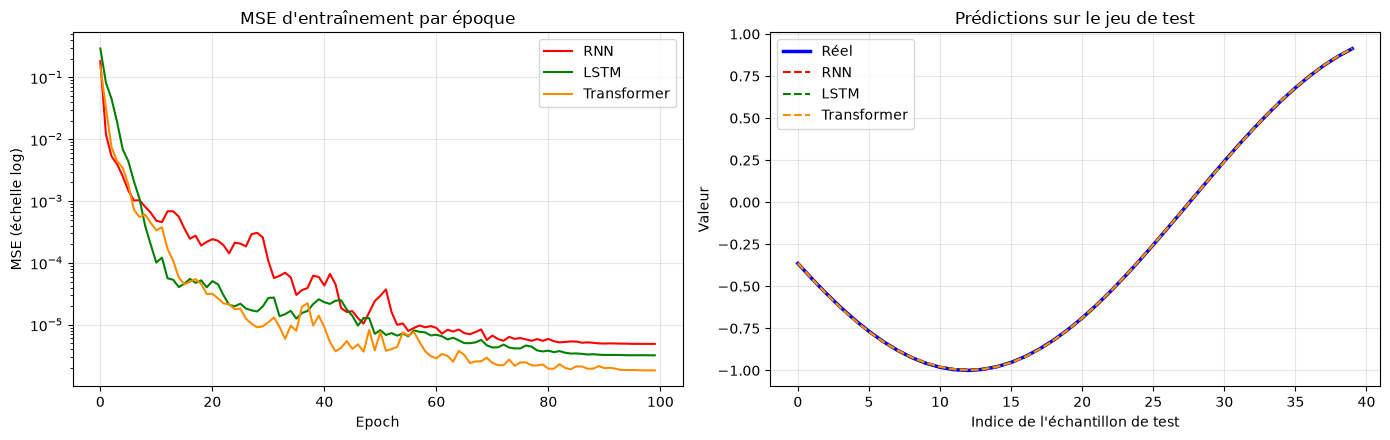

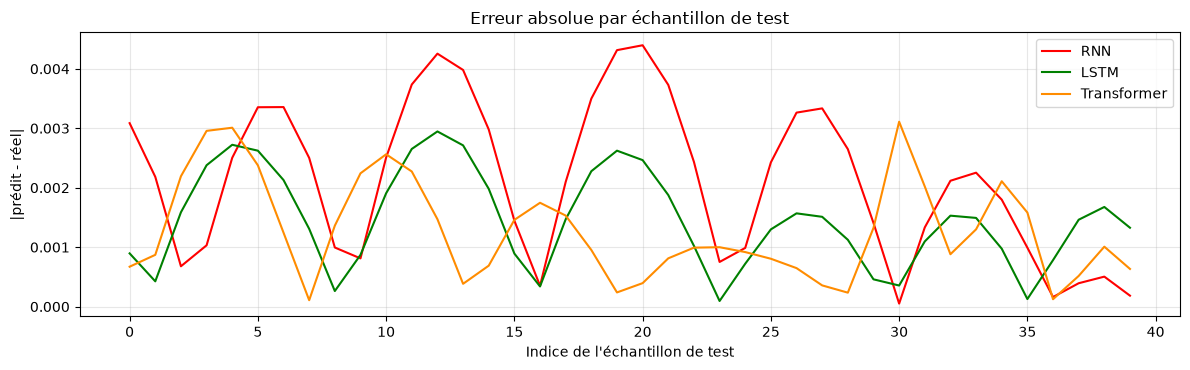

In [11]:
print(f"{'Modèle':<12} {'paramètres':>10} {'MSE test':>12} {'RMSE test':>10} {'MAE test':>10}")
for nom, r in resultats.items():
    print(f"{nom:<12} {r['params']:>10d} {r['mse']:>12.6f} {r['rmse']:>10.4f} {r['mae']:>10.4f}")

meilleur = min(resultats, key=lambda n: resultats[n]["mse"])
print("\nMSE de test la plus basse :", meilleur)

couleurs = {"RNN": "red", "LSTM": "green", "Transformer": "darkorange"}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for nom, r in resultats.items():
    axes[0].semilogy(r["historique"], label=nom, color=couleurs[nom])
axes[0].set_title("MSE d'entraînement par époque")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE (échelle log)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

reels = next(iter(resultats.values()))["reels"]
axes[1].plot(reels, color="blue", linewidth=2.5, label="Réel")
for nom, r in resultats.items():
    axes[1].plot(r["preds"], linestyle="--", color=couleurs[nom], label=nom)
axes[1].set_title("Prédictions sur le jeu de test")
axes[1].set_xlabel("Indice de l'échantillon de test")
axes[1].set_ylabel("Valeur")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Calcule l’erreur absolue pour chaque échantillon de test
plt.figure(figsize=(12, 3.8))
for nom, r in resultats.items():
    plt.plot(np.abs(r["preds"] - r["reels"]), label=nom, color=couleurs[nom])
plt.title("Erreur absolue par échantillon de test")
plt.xlabel("Indice de l'échantillon de test")
plt.ylabel("|prédit - réel|")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. GPT : poursuivre un texte

GPT-2 est un modèle génératif pré-entraîné fondé sur un décodeur Transformer. Il reçoit une amorce textuelle, calcule la distribution du token suivant, puis ajoute progressivement les nouveaux tokens générés.

In [12]:
from transformers import AutoTokenizer, AutoModelForCausalLM

nom_gpt = "gpt2"
tok_gpt = AutoTokenizer.from_pretrained(nom_gpt)
gpt = AutoModelForCausalLM.from_pretrained(nom_gpt).to(device)
gpt.eval()

# GPT-2 n’utilise pas de token de rembourrage ; le token de fin de texte est réutilisé.
tok_gpt.pad_token = tok_gpt.eos_token
gpt.config.pad_token_id = tok_gpt.pad_token_id

print("paramètres :", compter_parametres(gpt))
print("masque causal pour 5 tokens (1 = visible) :")
print(torch.tril(torch.ones(5, 5, dtype=torch.int)))

c:\Users\chaym\Documents\ai_5eme\Activité Pratique 4\.venv-1\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
c:\Users\chaym\Documents\ai_5eme\Activité Pratique 4\.venv-1\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\chaym\.cache\huggingface\hub\models--gpt2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administ

paramètres : 124439808
masque causal pour 5 tokens (1 = visible) :
tensor([[1, 0, 0, 0, 0],
        [1, 1, 0, 0, 0],
        [1, 1, 1, 0, 0],
        [1, 1, 1, 1, 0],
        [1, 1, 1, 1, 1]], dtype=torch.int32)


In [13]:
@torch.no_grad()
def continuer_texte(amorce, max_new_tokens=40, temperature=0.8, top_p=0.9, graine=0):
    entrees = tok_gpt(amorce, return_tensors="pt").to(device)
    torch.manual_seed(graine)
    sortie = gpt.generate(
        **entrees,
        max_new_tokens=max_new_tokens,
        do_sample=True,
        temperature=temperature,
        top_p=top_p,
        pad_token_id=tok_gpt.pad_token_id,
    )
    return tok_gpt.decode(sortie[0], skip_special_tokens=True)


@torch.no_grad()
def tokens_suivants(amorce, k=5):
    ids = tok_gpt(amorce, return_tensors="pt")["input_ids"].to(device)
    logits = gpt(ids).logits[0, -1]                 # Distribution associée uniquement au dernier token
    probas = torch.softmax(logits, dim=-1)
    p, i = torch.topk(probas, k)
    return [(tok_gpt.decode([idx]), prob.item()) for prob, idx in zip(p, i)]


amorces = [
    "Artificial intelligence can help people",
    "Press and organization",
    "The capital of Morocco is",
]

for amorce in amorces:
    ids = tok_gpt(amorce, return_tensors="pt")["input_ids"]
    print(f"\nAmorce : {amorce!r} ({ids.shape[1]} tokens, entrée {tuple(ids.shape)})")
    print("  candidats pour le token suivant :")
    for mot, p in tokens_suivants(amorce):
        print(f"    {p:6.2%} | {mot!r}")
    print("  texte généré :")
    print("   ", continuer_texte(amorce).replace("\n", " "))


Amorce : 'Artificial intelligence can help people' (6 tokens, entrée (1, 6))
  candidats pour le token suivant :
     7.17% | ' to'
     5.87% | ' with'
     4.97% | ' better'
     4.73% | ' understand'
     3.62% | ' make'
  texte généré :
    Artificial intelligence can help people understand what their behavior is like and how they respond to it. This helps the machine understand what is happening around them and to be able to make more effective decisions.  However, when you look

Amorce : 'Press and organization' (3 tokens, entrée (1, 3))
  candidats pour le token suivant :
     8.70% | '.'
     7.36% | ' of'
     6.78% | ','
     4.40% | '\n'
     2.50% | ':'
  texte généré :
    Press and organization, and their organization, the International Association of Women in the Field of Obstetrics and Gynecology (IASOP), is a group of women who have experience in a variety of areas of obst

Amorce : 'The capital of Morocco is' (5 tokens, entrée (1, 5))
  candidats pour le token suivan

Nous partons d’une phrase complète, puis nous demandons au modèle de produire plusieurs continuations. Chaque continuation utilise une nouvelle génération aléatoire.

In [14]:
amorce = "Artificial intelligence can help people"
ids = tok_gpt(amorce, return_tensors="pt")["input_ids"].to(device)

ids_modifie = ids.clone()
remplacant = tok_gpt.encode(" banana")[0]
if remplacant == ids[0, -1].item():
    remplacant = tok_gpt.encode(" house")[0]
ids_modifie[0, -1] = remplacant

with torch.no_grad():
    l1 = gpt(ids).logits
    l2 = gpt(ids_modifie).logits

avant_inchange = torch.allclose(l1[:, :-1], l2[:, :-1], atol=1e-4)
dernier_change = not torch.allclose(l1[:, -1], l2[:, -1], atol=1e-4)
print("positions précédentes inchangées :", avant_inchange)
print("dernière position modifiée       :", dernier_change)

positions précédentes inchangées : True
dernière position modifiée       : True


## 6. BERT : prédire un mot masqué

BERT est un modèle bidirectionnel pré-entraîné fondé sur un encodeur Transformer. Il peut exploiter simultanément le contexte situé à gauche et à droite du mot masqué.

In [15]:
from transformers import AutoModelForMaskedLM

nom_bert = "bert-base-multilingual-cased"
tok_bert = AutoTokenizer.from_pretrained(nom_bert)
bert = AutoModelForMaskedLM.from_pretrained(nom_bert).to(device)
bert.eval()

print("paramètres :", compter_parametres(bert))
print("token de masque :", tok_bert.mask_token, "| id :", tok_bert.mask_token_id)

c:\Users\chaym\Documents\ai_5eme\Activité Pratique 4\.venv-1\Lib\site-packages\huggingface_hub\file_download.py:150: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\chaym\.cache\huggingface\hub\models--bert-base-multilingual-cased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 202/202 [00:00<00:00, 413.05it/s]
[transformer

paramètres : 177974523
token de masque : [MASK] | id : 103


In [16]:
@torch.no_grad()
def completer_masque(texte, attendu=None, k=5):
    entrees = tok_bert(texte, return_tensors="pt").to(device)
    ids = entrees["input_ids"][0]
    positions = (ids == tok_bert.mask_token_id).nonzero(as_tuple=True)[0]
    assert len(positions) == 1, "une seule position [MASK] par phrase"
    pos = positions.item()

    logits = bert(**entrees).logits[0, pos]          # Scores de tous les tokens du vocabulaire
    probas = torch.softmax(logits, dim=-1)
    top_p, top_i = torch.topk(probas, k)

    print(f"\nTexte : {texte}  (entrée {tuple(entrees['input_ids'].shape)}, masque en position {pos})")
    candidats = []
    for p, i in zip(top_p, top_i):
        mot = tok_bert.convert_ids_to_tokens(i.item())
        candidats.append(mot)
        print(f"  {p.item():6.2%} | {mot:<12} | {texte.replace(tok_bert.mask_token, mot)}")

    if attendu is not None:
        if attendu in candidats:
            print(f"  mot attendu {attendu!r} : rang {candidats.index(attendu) + 1} sur {k}")
        else:
            print(f"  mot attendu {attendu!r} : absent du top {k}")
    return candidats


tests = [
    ("Rabat est la [MASK] du Maroc.", "capitale"),
    ("[MASK] est la capitale du Maroc.", "Rabat"),
    ("Casablanca est la plus grande [MASK] du Maroc.", "ville"),
    ("Le Maroc est situé en [MASK] du Nord.", "Afrique"),
    ("Marrakech est surnommée la ville [MASK].", "rouge"),
]

for texte, attendu in tests:
    completer_masque(texte, attendu)


Texte : Rabat est la [MASK] du Maroc.  (entrée (1, 9), masque en position 4)
  86.06% | capitale     | Rabat est la capitale du Maroc.
   5.19% | ville        | Rabat est la ville du Maroc.
   5.03% | préfecture   | Rabat est la préfecture du Maroc.
   0.85% | Rabat        | Rabat est la Rabat du Maroc.
   0.58% | capital      | Rabat est la capital du Maroc.
  mot attendu 'capitale' : rang 1 sur 5

Texte : [MASK] est la capitale du Maroc.  (entrée (1, 9), masque en position 1)
  67.50% | Casablanca   | Casablanca est la capitale du Maroc.
   7.24% | Rabat        | Rabat est la capitale du Maroc.
   7.19% | Elle         | Elle est la capitale du Maroc.
   2.15% | capitale     | capitale est la capitale du Maroc.
   1.59% | .            | . est la capitale du Maroc.
  mot attendu 'Rabat' : rang 2 sur 5

Texte : Casablanca est la plus grande [MASK] du Maroc.  (entrée (1, 11), masque en position 6)
  61.64% | ville        | Casablanca est la plus grande ville du Maroc.
  29.21% | Casabla

Dans cet exemple, BERT analyse une phrase contenant le token `[MASK]`. Les meilleurs candidats sont ensuite classés selon leur probabilité.

In [17]:
texte = "Rabat est la [MASK] du Maroc."
entrees = tok_bert(texte, return_tensors="pt").to(device)
ids = entrees["input_ids"]
pos = (ids[0] == tok_bert.mask_token_id).nonzero(as_tuple=True)[0].item()

ids_modifie = ids.clone()
ids_modifie[0, pos + 1] = tok_bert.convert_tokens_to_ids("de")   # "du" devient "de"

with torch.no_grad():
    l1 = bert(input_ids=ids, attention_mask=entrees["attention_mask"]).logits[0, pos]
    l2 = bert(input_ids=ids_modifie, attention_mask=entrees["attention_mask"]).logits[0, pos]

print("tokens :", tok_bert.convert_ids_to_tokens(ids[0]))
print("le masque tient compte du contexte de droite :", not torch.allclose(l1, l2, atol=1e-4))

tokens : ['[CLS]', 'Rabat', 'est', 'la', '[MASK]', 'du', 'Maroc', '.', '[SEP]']
le masque tient compte du contexte de droite : True


# Deuxième partie

## Exercice 1 : prédire la consommation électrique avec un Transformer

Cette partie applique un Transformer à une série réelle de consommation électrique. Le modèle reçoit les vingt-quatre valeurs précédentes pour estimer la puissance de l’heure suivante.

In [18]:
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHEMIN = "household_power_consumption.txt"
FENETRE = 24          # Nombre d’heures observées avant la cible
BATCH_SIZE = 64
EPOCHS = 20           # Nombre maximal d’époques
LR = 1e-3

print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Préparation des données

Nous chargeons les relevés horaires, conservons les variables utiles et construisons des fenêtres chronologiques de vingt-quatre heures. L’ordre temporel est préservé afin d’éviter toute évaluation sur des données accessibles pendant l’entraînement.

In [19]:
import pandas as pd
import zipfile
import urllib
import os

URL_UCI = ("https://archive.ics.uci.edu/static/public/235/"
           "individual+household+electric+power+consumption.zip")


def verifier_fichier(chemin):
    if os.path.exists(chemin):
        return
    print("Fichier absent, tentative de téléchargement depuis UCI...")
    try:
        archive, _ = urllib.request.urlretrieve(URL_UCI, "household_power.zip")
        with zipfile.ZipFile(archive) as z:
            z.extract(os.path.basename(chemin))
    except Exception as e:
        raise FileNotFoundError(
            f"Impossible de récupérer {chemin} ({e}). Télécharge l'archive sur "
            "https://archive.ics.uci.edu/dataset/235 et place le .txt à côté du notebook."
        )


verifier_fichier(CHEMIN)

# Charge uniquement les trois colonnes utiles du fichier.
df = pd.read_csv(CHEMIN, sep=";", na_values=["?"], low_memory=False,
                 usecols=["Date", "Time", "Global_active_power"])

df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"], format="%d/%m/%Y %H:%M:%S")
puissance = pd.to_numeric(df["Global_active_power"], errors="coerce")
puissance.index = pd.DatetimeIndex(df["datetime"])

print("mesures à la minute :", len(df), "| manquantes :", int(puissance.isna().sum()))
print("période :", puissance.index.min(), "->", puissance.index.max())

mesures à la minute : 2075259 | manquantes : 25979
période : 2006-12-16 17:24:00 -> 2010-11-26 21:02:00


In [20]:
# Calcule la puissance moyenne horaire lorsque suffisamment de relevés sont disponibles.
horaire = puissance.resample("h").agg(["mean", "count"])
serie = horaire["mean"].where(horaire["count"] >= 45)

# Découpe les données dans l’ordre temporel : 70 % entraînement, 15 % validation et 15 % test.
n = len(serie)
fin_train = int(0.70 * n)
fin_val = int(0.85 * n)

# Calcule les statistiques de normalisation sur l’entraînement uniquement.
moyenne = float(serie.iloc[:fin_train].mean())
ecart_type = float(serie.iloc[:fin_train].std())
valeurs = ((serie - moyenne) / ecart_type).to_numpy()

print(f"heures : {n} | manquantes : {int(serie.isna().sum())}")
print(f"train : {moyenne:.3f} kW de moyenne, {ecart_type:.3f} kW d'écart type")


def construire_fenetres(valeurs, fenetre):
    # Chaque entrée contient `fenetre` heures consécutives ; la cible est l’heure suivante.
    # Écarte les fenêtres contenant une mesure manquante.
    X, y, idx_cibles = [], [], []
    for i in range(fenetre, len(valeurs)):
        sequence = valeurs[i - fenetre:i]
        cible = valeurs[i]
        if np.isfinite(sequence).all() and np.isfinite(cible):
            X.append(sequence)
            y.append(cible)
            idx_cibles.append(i)
    X = torch.tensor(np.array(X), dtype=torch.float32).unsqueeze(-1)    # Entrées converties en tenseur de forme (N, fenetre, 1)
    y = torch.tensor(np.array(y), dtype=torch.float32).unsqueeze(-1)    # Cibles converties en tenseur de forme (N, 1)
    return X, y, np.array(idx_cibles)


X, y, idx_cibles = construire_fenetres(valeurs, FENETRE)

# Sépare les données selon l’heure cible afin que le test reste entièrement futur.
train_mask = idx_cibles < fin_train
val_mask = (idx_cibles >= fin_train) & (idx_cibles < fin_val)
test_mask = idx_cibles >= fin_val

X_train, y_train = X[train_mask], y[train_mask]
X_val, y_val = X[val_mask], y[val_mask]
X_test, y_test = X[test_mask], y[test_mask]

g = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True, generator=g)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=BATCH_SIZE)

print("\nX :", tuple(X.shape), "| y :", tuple(y.shape))
print("train :", tuple(X_train.shape), "| val :", tuple(X_val.shape), "| test :", tuple(X_test.shape))

heures : 34589 | manquantes : 438
train : 1.086 kW de moyenne, 0.929 kW d'écart type

X : (33791, 24, 1) | y : (33791, 1)
train : (23805, 24, 1) | val : (5054, 24, 1) | test : (4932, 24, 1)


## 2. Modèle : `EnergyTransformer`

Le modèle projette les mesures normalisées dans une représentation de dimension 32. Des vecteurs de position appris rendent la position de chaque heure identifiable.

L’encodeur comporte deux couches Transformer avec quatre têtes d’attention. La représentation de la dernière heure traverse une couche de sortie pour produire la consommation prévue.

In [21]:
class EnergyTransformer(nn.Module):
    def __init__(self, longueur=24, d_model=32, nb_tetes=4, d_ff=128, nb_couches=2, dropout=0.1):
        super().__init__()
        self.projection = nn.Linear(1, d_model)
        self.positions = nn.Embedding(longueur, d_model)
        couche = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nb_tetes, dim_feedforward=d_ff,
            dropout=dropout, batch_first=True,
        )
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, 1)

    def forward(self, x):                                   # Entrée de forme (B, 24, 1)
        T = x.size(1)
        h = self.projection(x)                              # Projection de forme (B, 24, 32)
        h = h + self.positions(torch.arange(T, device=x.device)).unsqueeze(0)
        h = self.encodeur(h)                                # Encodage de forme (B, 24, 32)
        return self.sortie(h[:, -1, :])                     # Prédiction normalisée de forme (B, 1)

    @torch.no_grad()
    def formes(self, x):
        # Réexécute le calcul complet afin d’afficher les formes intermédiaires.
        etapes = [("entrée", tuple(x.shape))]
        h = self.projection(x)
        etapes.append(("après projection", tuple(h.shape)))
        h = h + self.positions(torch.arange(x.size(1), device=x.device)).unsqueeze(0)
        h = self.encodeur(h)
        etapes.append(("après Transformer Encoder", tuple(h.shape)))
        etapes.append(("prédiction", tuple(self.sortie(h[:, -1, :]).shape)))
        return etapes


torch.manual_seed(SEED)
modele = EnergyTransformer(longueur=FENETRE).to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

modele.eval()
for nom, forme in modele.formes(X_test[:4].to(device)):
    print(f"  {nom:<28} {forme}")

paramètres : 26273
  entrée                       (4, 24, 1)
  après projection             (4, 24, 32)
  après Transformer Encoder    (4, 24, 32)
  prédiction                   (4, 1)


## 3. Entraînement

L’entraînement minimise l’erreur quadratique entre la consommation prédite et la consommation réelle. La validation permet de conserver la meilleure période et d’arrêter l’apprentissage lorsque les performances cessent de progresser.

Epoch  1 | MSE train : 0.4663 | MSE val : 0.4052  <- meilleur modèle
Epoch  2 | MSE train : 0.4286 | MSE val : 0.3912  <- meilleur modèle
Epoch  3 | MSE train : 0.4219 | MSE val : 0.3942
Epoch  4 | MSE train : 0.4188 | MSE val : 0.3855  <- meilleur modèle
Epoch  5 | MSE train : 0.4146 | MSE val : 0.3943
Epoch  6 | MSE train : 0.4129 | MSE val : 0.3939
Epoch  7 | MSE train : 0.4095 | MSE val : 0.3898
Epoch  8 | MSE train : 0.4085 | MSE val : 0.3821  <- meilleur modèle
Epoch  9 | MSE train : 0.4082 | MSE val : 0.3975
Epoch 10 | MSE train : 0.4037 | MSE val : 0.3824
Epoch 11 | MSE train : 0.4032 | MSE val : 0.3868
Epoch 12 | MSE train : 0.4000 | MSE val : 0.3902
Epoch 13 | MSE train : 0.4023 | MSE val : 0.3770  <- meilleur modèle
Epoch 14 | MSE train : 0.3981 | MSE val : 0.3855
Epoch 15 | MSE train : 0.3991 | MSE val : 0.3835
Epoch 16 | MSE train : 0.3971 | MSE val : 0.3781
Epoch 17 | MSE train : 0.3962 | MSE val : 0.3761  <- meilleur modèle
Epoch 18 | MSE train : 0.3964 | MSE val : 0.386

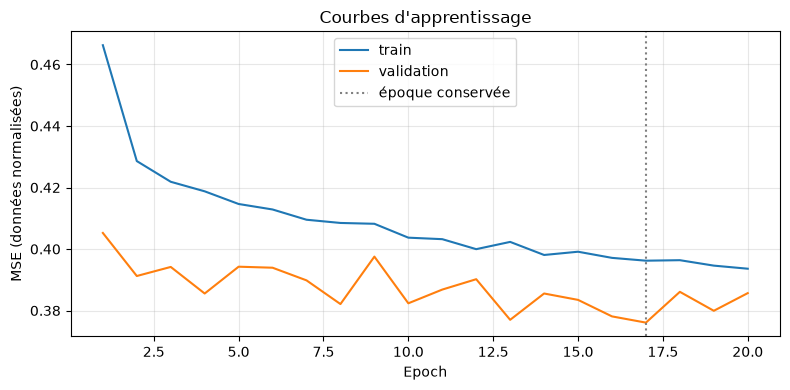

In [22]:
import copy

critere = nn.MSELoss()
optimiseur = torch.optim.Adam(modele.parameters(), lr=LR)


def passe(modele, loader, optimiseur=None):
    # Exécute une passe sur les données : entraînement si un optimiseur est fourni.
    entrainement = optimiseur is not None
    modele.train(entrainement)
    somme, n = 0.0, 0
    with torch.set_grad_enabled(entrainement):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            perte = critere(modele(xb), yb)
            if entrainement:
                optimiseur.zero_grad()
                perte.backward()
                optimiseur.step()
            somme += perte.item() * len(xb)
            n += len(xb)
    return somme / n


hist_train, hist_val = [], []
meilleure_val, meilleure_epoch, meilleurs_poids = float("inf"), 0, None

for epoch in range(1, EPOCHS + 1):
    perte_train = passe(modele, train_loader, optimiseur)
    perte_val = passe(modele, val_loader)
    hist_train.append(perte_train)
    hist_val.append(perte_val)

    marque = ""
    if perte_val < meilleure_val:
        meilleure_val, meilleure_epoch = perte_val, epoch
        meilleurs_poids = copy.deepcopy(modele.state_dict())
        marque = "  <- meilleur modèle"
    print(f"Epoch {epoch:2d} | MSE train : {perte_train:.4f} | MSE val : {perte_val:.4f}{marque}")

modele.load_state_dict(meilleurs_poids)
print(f"\nModèle conservé : époque {meilleure_epoch} (MSE val normalisée = {meilleure_val:.4f})")

plt.figure(figsize=(8, 4))
plt.plot(range(1, EPOCHS + 1), hist_train, label="train")
plt.plot(range(1, EPOCHS + 1), hist_val, label="validation")
plt.axvline(meilleure_epoch, color="gray", linestyle=":", label="époque conservée")
plt.xlabel("Epoch")
plt.ylabel("MSE (données normalisées)")
plt.title("Courbes d'apprentissage")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Évaluation sur le test, en kW

Les résultats sont évalués sur la période de test, puis remis à l’échelle des kilowatts.

- La persistance reprend la dernière valeur observée dans la fenêtre.
- La référence journalière reprend la valeur observée vingt-quatre heures auparavant.
- Les prédictions du Transformer sont comparées à ces deux références.

In [23]:
def vers_kw(v):
    return v * ecart_type + moyenne


@torch.no_grad()
def predire(modele, loader):
    modele.eval()
    return torch.cat([modele(xb.to(device)).cpu() for xb, _ in loader]).squeeze(1)


def metriques(reel_kw, pred_kw):
    erreur = pred_kw - reel_kw
    return erreur.abs().mean().item(), math.sqrt((erreur ** 2).mean().item())


reel_kw = vers_kw(y_test.squeeze(1))
pred_transfo = vers_kw(predire(modele, test_loader))
pred_persistance = vers_kw(X_test[:, -1, 0])
pred_journaliere = vers_kw(X_test[:, -24, 0])

resultats = {
    "Transformer": metriques(reel_kw, pred_transfo),
    "Persistance": metriques(reel_kw, pred_persistance),
    "Réf. journalière": metriques(reel_kw, pred_journaliere),
}

print(f"Échantillons de test : {len(reel_kw)}")
print(f"{'Modèle':<18} {'MAE (kW)':>10} {'RMSE (kW)':>10}")
for nom, (mae, rmse) in resultats.items():
    print(f"{nom:<18} {mae:>10.4f} {rmse:>10.4f}")

mae_t, rmse_t = resultats["Transformer"]
for ref in ("Persistance", "Réf. journalière"):
    mae_r, rmse_r = resultats[ref]
    print(f"\nTransformer vs {ref} : MAE {100 * (mae_r - mae_t) / mae_r:+.1f} % | "
          f"RMSE {100 * (rmse_r - rmse_t) / rmse_r:+.1f} % (positif = le Transformer fait mieux)")

Échantillons de test : 4932
Modèle               MAE (kW)  RMSE (kW)
Transformer            0.3407     0.4877
Persistance            0.3892     0.5884
Réf. journalière       0.5133     0.7639

Transformer vs Persistance : MAE +12.5 % | RMSE +17.1 % (positif = le Transformer fait mieux)

Transformer vs Réf. journalière : MAE +33.6 % | RMSE +36.2 % (positif = le Transformer fait mieux)


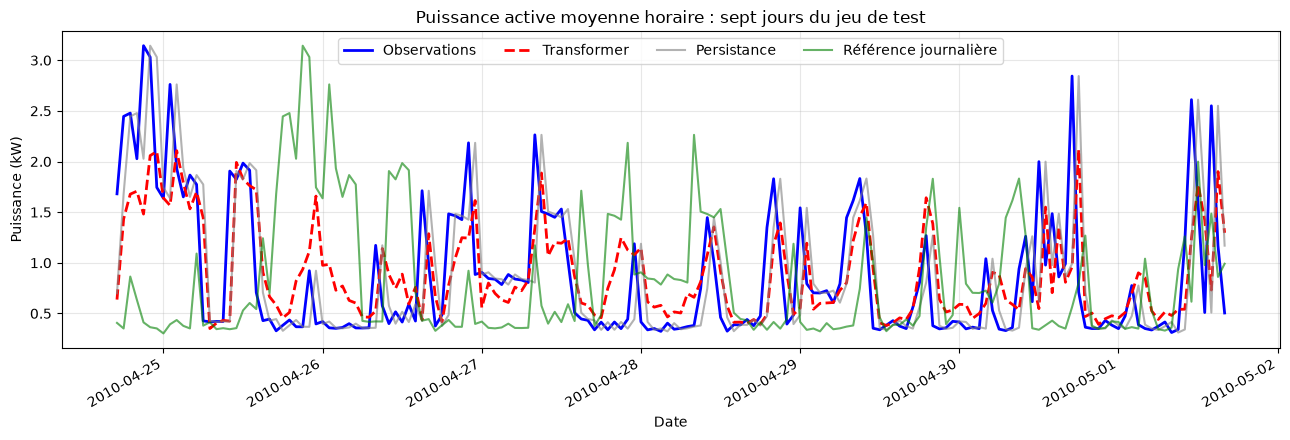

In [24]:
# Sélectionne sept jours consécutifs, soit 168 heures du test.
idx_test = idx_cibles[test_mask]
consecutifs = np.diff(idx_test) == 1


def debut_bloc(longueur=168):
    # Recherche la première séquence de longueur demandée sans trou temporel.
    run = 0
    for k, ok in enumerate(consecutifs):
        run = run + 1 if ok else 0
        if run >= longueur - 1:
            return k - (longueur - 2)
    return None


debut = debut_bloc(168)
if debut is None:
    print("Pas de bloc de 168 heures consécutives dans le test.")
else:
    sel = slice(debut, debut + 168)
    dates = serie.index[idx_test[sel]]

    plt.figure(figsize=(13, 4.5))
    plt.plot(dates, reel_kw[sel], label="Observations", color="blue", linewidth=2)
    plt.plot(dates, pred_transfo[sel], label="Transformer", color="red", linestyle="--", linewidth=2)
    plt.plot(dates, pred_persistance[sel], label="Persistance", color="gray", alpha=0.6)
    plt.plot(dates, pred_journaliere[sel], label="Référence journalière", color="green", alpha=0.6)
    plt.title("Puissance active moyenne horaire : sept jours du jeu de test")
    plt.xlabel("Date")
    plt.ylabel("Puissance (kW)")
    plt.legend(ncol=4, loc="upper center")
    plt.grid(True, alpha=0.3)
    plt.gcf().autofmt_xdate()
    plt.tight_layout()
    plt.show()

In [25]:
# 1. Pas de fuite temporelle : train, validation et test se suivent dans le temps.
idx_train, idx_val = idx_cibles[train_mask], idx_cibles[val_mask]
assert idx_train.max() < fin_train <= idx_val.min() and idx_val.max() < fin_val <= idx_test.min()
print("1. cibles train < validation < test : ok")

# 2. La normalisation vient du train : on la recalcule à la main.
brut_train = serie.iloc[:fin_train].dropna()
assert abs(brut_train.mean() - moyenne) < 1e-9 and abs(brut_train.std() - ecart_type) < 1e-9
print(f"2. moyenne/écart type calculés sur le train seulement : ok ({moyenne:.3f} / {ecart_type:.3f} kW)")

# 3. Alignement d'une fenêtre : X = 24 heures avant l'heure cible, y = l'heure cible.
k = 100
i = idx_test[k]
assert np.allclose(X_test[k, :, 0].numpy(), valeurs[i - FENETRE:i]) and np.isclose(y_test[k].item(), valeurs[i])
print(f"3. fenêtre test {k} : heures {serie.index[i - FENETRE]} -> {serie.index[i - 1]}, cible {serie.index[i]} : ok")

# 4. En eval(), deux passes donnent la même sortie (le dropout est coupé).
modele.eval()
with torch.no_grad():
    a = modele(X_test[:8].to(device))
    b = modele(X_test[:8].to(device))
assert torch.allclose(a, b)
print("4. sorties identiques en eval() : ok | forme", tuple(a.shape))

# 5. Quelques prédictions en kW.
print(f"\n{'heure cible':<20} {'réel':>7} {'Transf.':>8} {'persist.':>9} {'jour -1':>8}")
for k in (0, 1, 2, 3, 4):
    print(f"{str(serie.index[idx_test[k]]):<20} {reel_kw[k]:>7.3f} {pred_transfo[k]:>8.3f} "
          f"{pred_persistance[k]:>9.3f} {pred_journaliere[k]:>8.3f}")

1. cibles train < validation < test : ok
2. moyenne/écart type calculés sur le train seulement : ok (1.086 / 0.929 kW)
3. fenêtre test 100 : heures 2010-04-27 21:00:00 -> 2010-04-28 20:00:00, cible 2010-04-28 21:00:00 : ok
4. sorties identiques en eval() : ok | forme (8, 1)

heure cible             réel  Transf.  persist.  jour -1
2010-04-24 17:00:00    1.681    0.637     0.699    0.406
2010-04-24 18:00:00    2.445    1.433     1.681    0.351
2010-04-24 19:00:00    2.478    1.678     2.445    0.864
2010-04-24 20:00:00    2.028    1.707     2.478    0.634
2010-04-24 21:00:00    3.143    1.481     2.028    0.412


## Exercice 2 : construire un mini-GPT pour générer du texte caractère par caractère

Dans cet exercice, le niveau de modélisation est différent : chaque caractère est traité comme un token. Le modèle apprend à prédire le caractère suivant à partir de la séquence précédente.

In [26]:
import json
import math
import os
import re

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

LONGUEUR = 64        # Nombre de caractères contenus dans chaque séquence
D_MODEL = 64
NB_TETES = 4
NB_BLOCS = 2
D_FF = 256
DROPOUT = 0.1

TAILLE_LOT = 64
ETAPES = 2000        # Nombre de mises à jour ; les fenêtres sont tirées au hasard
LR = 3e-3

print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Préparation des données

Le texte est nettoyé, limité si nécessaire à sa partie principale, puis converti en séquences numériques. Chaque caractère reçoit un identifiant unique dans un vocabulaire construit à partir du corpus.

In [27]:
def charger_corpus(chemin="corpus.txt", source="Activité Pratique N°4 - Architecture Transformer.ipynb"):
    if not os.path.exists(chemin):
        if not os.path.exists(source):
            raise FileNotFoundError(
                f"{chemin} introuvable. Crée-le avec quelques pages de texte "
                f"(ou place {source} dans le dossier)."
            )
        with open(source, encoding="utf-8") as f:
            nb = json.load(f)
        morceaux = []
        for cellule in nb["cells"]:
            if cellule["cell_type"] == "markdown":
                t = "".join(cellule["source"])
                t = re.sub(r"!\[[^\]]*\]\(data:[^)]*\)", "", t)   # Retire les images encodées en base64
                if t.strip():
                    morceaux.append(t.strip())
        with open(chemin, "w", encoding="utf-8") as f:
            f.write("\n\n".join(morceaux))
        print(f"{chemin} créé à partir de {source}")
    with open(chemin, encoding="utf-8") as f:
        return f.read()


texte = charger_corpus()

caracteres = sorted(set(texte))
stoi = {c: i for i, c in enumerate(caracteres)}
itos = {i: c for c, i in stoi.items()}
TAILLE_VOCAB = len(caracteres)

tokens = torch.tensor([stoi[c] for c in texte], dtype=torch.long)

n_train = int(0.9 * len(tokens))
tokens_train, tokens_val = tokens[:n_train], tokens[n_train:]

print("caractères dans le corpus :", len(texte))
print("taille du vocabulaire     :", TAILLE_VOCAB)
print("train :", len(tokens_train), "| val :", len(tokens_val))
print("perte d'un modèle qui devine au hasard : ln(V) =", round(math.log(TAILLE_VOCAB), 3))


def encoder(s):
    return [stoi[c] for c in s if c in stoi]      # Ignore les caractères absents du vocabulaire


def decoder(ids):
    return "".join(itos[i] for i in ids)


def lot(donnees, taille_lot, gen):
    # Tire des fenêtres aléatoires : y contient x décalé d’un caractère.
    debuts = torch.randint(0, len(donnees) - LONGUEUR, (taille_lot,), generator=gen)
    x = torch.stack([donnees[d:d + LONGUEUR] for d in debuts])
    y = torch.stack([donnees[d + 1:d + LONGUEUR + 1] for d in debuts])
    return x.to(device), y.to(device)


gen_demo = torch.Generator().manual_seed(SEED)
x, y = lot(tokens_train, 4, gen_demo)
print("\nx :", tuple(x.shape), "| y :", tuple(y.shape))
assert torch.equal(x[:, 1:], y[:, :-1])           # Vérifie que y correspond à x décalé d’une position
print("entrée  :", repr(decoder(x[0, :20].tolist())))
print("cible   :", repr(decoder(y[0, :20].tolist())))

caractères dans le corpus : 10825
taille du vocabulaire     : 98
train : 9742 | val : 1083
perte d'un modèle qui devine au hasard : ln(V) = 4.585

x : (4, 64) | y : (4, 64)
entrée  : 'ns : les logits `(B,'
cible   : 's : les logits `(B, '


## 2. Architecture du modèle

Le mini-GPT comprend une représentation des caractères, une représentation des positions et un bloc Transformer décodeur. Un masque causal empêche une position d’accéder aux caractères situés après elle.

À chaque position, le réseau prédit la distribution du caractère suivant.

In [28]:
class BlocGPT(nn.Module):
    def __init__(self, d_model=D_MODEL, nb_tetes=NB_TETES, d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.norm1 = nn.LayerNorm(d_model)
        self.attention = nn.MultiheadAttention(d_model, nb_tetes, dropout=dropout, batch_first=True)
        self.norm2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(
            nn.Linear(d_model, d_ff),
            nn.GELU(),
            nn.Linear(d_ff, d_model),
            nn.Dropout(dropout),
        )

    def forward(self, x, masque):                           # Entrée de forme (B, T, 64)
        h = self.norm1(x)
        att, _ = self.attention(h, h, h, attn_mask=masque, need_weights=False)
        x = x + att                                         # Première connexion résiduelle
        x = x + self.mlp(self.norm2(x))                     # Deuxième connexion résiduelle
        return x


class MiniGPT(nn.Module):
    def __init__(self, taille_vocab, longueur_max=LONGUEUR, d_model=D_MODEL,
                 nb_tetes=NB_TETES, nb_blocs=NB_BLOCS, d_ff=D_FF, dropout=DROPOUT, causal=True):
        super().__init__()
        self.causal = causal
        self.emb_car = nn.Embedding(taille_vocab, d_model)
        self.emb_pos = nn.Embedding(longueur_max, d_model)
        self.drop = nn.Dropout(dropout)
        self.blocs = nn.ModuleList([BlocGPT(d_model, nb_tetes, d_ff, dropout) for _ in range(nb_blocs)])
        self.norm_finale = nn.LayerNorm(d_model)
        self.sortie = nn.Linear(d_model, taille_vocab)

    def forward(self, ids, causal=None):                    # Identifiants de forme (B, T)
        # Permet de forcer le masque causal lors de l’expérience de contrôle.
        causal = self.causal if causal is None else causal
        B, T = ids.shape
        positions = torch.arange(T, device=ids.device)
        h = self.drop(self.emb_car(ids) + self.emb_pos(positions))     # Représentations cachées de forme (B, T, 64)

        masque = None
        if causal:
            masque = torch.triu(torch.ones(T, T, dtype=torch.bool, device=ids.device), diagonal=1)

        for bloc in self.blocs:
            h = bloc(h, masque)                             # Représentations cachées de forme (B, T, 64)
        h = self.norm_finale(h)                             # Représentations cachées de forme (B, T, 64)
        return self.sortie(h)                               # Distribution des caractères pour chaque position


torch.manual_seed(SEED)
modele = MiniGPT(TAILLE_VOCAB).to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

x, y = lot(tokens_train, 4, gen_demo)
logits = modele(x)
print("ids     :", tuple(x.shape))
print("logits  :", tuple(logits.shape), "= (batch, 64, taille_vocabulaire)")

perte_init = F.cross_entropy(logits.reshape(-1, TAILLE_VOCAB), y.reshape(-1)).item()
print(f"perte avant entraînement : {perte_init:.3f} (ln V = {math.log(TAILLE_VOCAB):.3f})")

paramètres : 116834
ids     : (4, 64)
logits  : (4, 64, 98) = (batch, 64, taille_vocabulaire)
perte avant entraînement : 4.806 (ln V = 4.585)


## 3. Entraînement

Des fenêtres aléatoires sont extraites du corpus. L’optimiseur ajuste les paramètres afin que le caractère cible ait une forte probabilité à chaque position.

In [29]:
@torch.no_grad()
def evaluer(modele, donnees, nb_lots=40, causal=None):
    modele.eval()
    gen = torch.Generator().manual_seed(123)         # Réutilise les mêmes fenêtres aléatoires à chaque appel
    pertes, justes, total = [], 0, 0
    for _ in range(nb_lots):
        x, y = lot(donnees, TAILLE_LOT, gen)
        logits = modele(x, causal)
        pertes.append(F.cross_entropy(logits.reshape(-1, TAILLE_VOCAB), y.reshape(-1)).item())
        justes += (logits.argmax(dim=-1) == y).sum().item()
        total += y.numel()
    perte = sum(pertes) / len(pertes)
    return perte, math.exp(perte), justes / total


def entrainer(modele, etapes, lr=LR, afficher_tous_les=250, graine=SEED):
    optimiseur = torch.optim.AdamW(modele.parameters(), lr=lr, weight_decay=0.01)
    planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=etapes, eta_min=lr / 10)
    gen = torch.Generator().manual_seed(graine)
    historique = []

    for etape in range(1, etapes + 1):
        modele.train()
        x, y = lot(tokens_train, TAILLE_LOT, gen)
        logits = modele(x)                                           # Logits de forme (B, 64, V)
        perte = F.cross_entropy(logits.reshape(-1, TAILLE_VOCAB), y.reshape(-1))

        optimiseur.zero_grad()
        perte.backward()
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        optimiseur.step()
        planning.step()

        if etape % afficher_tous_les == 0 or etape == etapes:
            p_val, ppl_val, acc_val = evaluer(modele, tokens_val)
            historique.append((etape, perte.item(), p_val))
            print(f"étape {etape:5d} | perte train {perte.item():.3f} | perte val {p_val:.3f} "
                  f"| perplexité val {ppl_val:6.2f} | exactitude val {acc_val:.1%}")
    return historique


historique = entrainer(modele, ETAPES)

étape   250 | perte train 2.089 | perte val 2.359 | perplexité val  10.58 | exactitude val 32.6%
étape   500 | perte train 1.344 | perte val 2.140 | perplexité val   8.50 | exactitude val 42.6%
étape   750 | perte train 0.978 | perte val 2.299 | perplexité val   9.96 | exactitude val 44.9%
étape  1000 | perte train 0.797 | perte val 2.488 | perplexité val  12.03 | exactitude val 46.2%
étape  1250 | perte train 0.714 | perte val 2.666 | perplexité val  14.39 | exactitude val 46.2%
étape  1500 | perte train 0.659 | perte val 2.762 | perplexité val  15.84 | exactitude val 46.4%
étape  1750 | perte train 0.625 | perte val 2.828 | perplexité val  16.91 | exactitude val 46.9%
étape  2000 | perte train 0.606 | perte val 2.870 | perplexité val  17.64 | exactitude val 46.8%


In [30]:
p_tr, ppl_tr, acc_tr = evaluer(modele, tokens_train)
p_va, ppl_va, acc_va = evaluer(modele, tokens_val)
print(f"{'':<12} {'perte':>7} {'perplexité':>11} {'exactitude':>11}")
print(f"{'train':<12} {p_tr:>7.3f} {ppl_tr:>11.2f} {acc_tr:>11.1%}")
print(f"{'validation':<12} {p_va:>7.3f} {ppl_va:>11.2f} {acc_va:>11.1%}")
print(f"{'hasard':<12} {math.log(TAILLE_VOCAB):>7.3f} {TAILLE_VOCAB:>11d} {1 / TAILLE_VOCAB:>11.1%}")

               perte  perplexité  exactitude
train          0.267        1.31       92.4%
validation     2.870       17.64       46.8%
hasard         4.585          98        1.0%


## 4. Génération et température

La génération commence avec une amorce. À chaque étape, le modèle calcule les probabilités du caractère suivant. La température contrôle leur concentration :

- une température faible rend les choix plus déterministes ;
- une température élevée augmente la variété des choix.

In [31]:
@torch.no_grad()
def generer(modele, amorce, nb_car=200, temperature=1.0, graine=0):
    modele.eval()
    ids = encoder(amorce)
    if not ids:                                       # Aucune lettre de l’amorce n’est présente dans le vocabulaire
        ids = encoder(texte[:20])
    sortie = torch.tensor([ids], device=device)
    gen = torch.Generator().manual_seed(graine)

    for _ in range(nb_car):
        contexte = sortie[:, -LONGUEUR:]              # La génération reste limitée à la longueur maximale autorisée
        logits = modele(contexte)[0, -1] / temperature
        probas = torch.softmax(logits.cpu(), dim=-1)
        suivant = torch.multinomial(probas, 1, generator=gen)
        sortie = torch.cat([sortie, suivant.view(1, 1).to(device)], dim=1)
    return decoder(sortie[0].tolist())


AMORCE = "Le Transformer "

for temperature in (0.5, 1.0, 1.5):
    print(f"\n===== température {temperature} =====")
    print(generer(modele, AMORCE, nb_car=200, temperature=temperature))


===== température 0.5 =====
Le Transformer encodeur (2 têtes, `d_model = 16`)
5. GPT : pers ranseignées à partir de l'entraînement ?
5. La cible étant une fenêtre décalée d'un caractère : `y = tokens[i + 1 : i + 65]`.

## 2. Modèle

Bloc GPT (

===== température 1.0 =====
Le Transformer encodeur (0 à 23),     -> (16eLU)
     -> LayerNorm -> 32 -> deux             -> (Ge connexion rédirements (24 vales apparti" les 60. On les entraînement (sans masque dans la séquence en sur CPU. Seur

===== température 1.5 =====
Le Transformer encodeur : une heur l'heure vocabule et dire token du vocabulaire, ation au notlise moins (même ceausal est utilise à plus b"ance se). La nortie. Se-modèle positions deuxième partion peut bouger.

Vér


In [32]:
# 1. Causalité : en eval(), changer un caractère futur ne doit pas toucher les logits d'avant.
modele.eval()
x, _ = lot(tokens_val, 4, torch.Generator().manual_seed(1))
k = 40
x_modifie = x.clone()
x_modifie[:, k] = (x[:, k] + 1) % TAILLE_VOCAB        # on change le caractère en position k

with torch.no_grad():
    l1, l2 = modele(x), modele(x_modifie)

avant = torch.allclose(l1[:, :k], l2[:, :k], atol=1e-5)
apres = not torch.allclose(l1[:, k:], l2[:, k:], atol=1e-5)
print(f"1. positions 0..{k - 1} inchangées : {avant} | positions {k}..{LONGUEUR - 1} modifiées : {apres}")
assert avant and apres

# 2. Formes
assert logits.shape == (4, LONGUEUR, TAILLE_VOCAB)
print("2. formes ok :", tuple(l1.shape))

# 3. Les probabilités du caractère suivant somment à 1
p = torch.softmax(l1[0, -1], dim=-1)
print("3. somme des probabilités :", round(p.sum().item(), 6))

# 4. Trois prédictions sur un exemple de validation
x1, y1 = lot(tokens_val, 1, torch.Generator().manual_seed(5))
with torch.no_grad():
    top = torch.topk(torch.softmax(modele(x1)[0], dim=-1), 3, dim=-1)
print("\n4. contexte :", repr(decoder(x1[0, :30].tolist())))
for pos in (10, 20, 29):
    ctx = decoder(x1[0, :pos + 1].tolist())[-12:]
    cands = ", ".join(f"{itos[i.item()]!r} {pr.item():.0%}" for pr, i in zip(top.values[pos], top.indices[pos]))
    print(f"   ...{ctx!r} -> attendu {itos[y1[0, pos].item()]!r} | top 3 : {cands}")

1. positions 0..39 inchangées : True | positions 40..63 modifiées : True
2. formes ok : (4, 64, 98)
3. somme des probabilités : 1.0

4. contexte : 'te (1.5) : distribution plus p'
   ...'te (1.5) : ' -> attendu 'd' | top 3 : 'l' 32%, 'p' 26%, 'E' 21%
   ...': distributi' -> attendu 'o' | top 3 : 'o' 99%, 'h' 0%, 'n' 0%
   ...'ution plus p' -> attendu 'l' | top 3 : 'a' 90%, 'o' 5%, 'e' 3%


## Expérience : comportement sans masque causal

Le masque causal est retiré pendant une expérience de contrôle. Sans ce masque, la prédiction d’une position peut dépendre des caractères situés à sa droite. Cette modification rend le modèle incompatible avec une génération textuelle respectant l’ordre temporel.

In [33]:
ETAPES_SANS_MASQUE = 600

torch.manual_seed(SEED)
sans_masque = MiniGPT(TAILLE_VOCAB, causal=False).to(device)
entrainer(sans_masque, ETAPES_SANS_MASQUE, afficher_tous_les=200)

print(f"\n{'modèle':<34} {'perte val':>10} {'exactitude':>11}")
for nom, m, causal in [
    ("sans masque, évalué sans masque", sans_masque, False),
    ("sans masque, évalué avec masque", sans_masque, True),
    ("avec masque (modèle principal)", modele, True),
]:
    p, _, acc = evaluer(m, tokens_val, causal=causal)
    print(f"{nom:<34} {p:>10.3f} {acc:>11.1%}")

print("\nGénération du modèle sans masque (température 1.0) :")
print(generer(sans_masque, AMORCE, nb_car=120, temperature=1.0))

étape   200 | perte train 0.239 | perte val 0.154 | perplexité val   1.17 | exactitude val 96.6%
étape   400 | perte train 0.080 | perte val 0.066 | perplexité val   1.07 | exactitude val 98.6%
étape   600 | perte train 0.067 | perte val 0.064 | perplexité val   1.07 | exactitude val 98.7%

modèle                              perte val  exactitude
sans masque, évalué sans masque         0.064       98.7%
sans masque, évalué avec masque         6.386        8.9%
avec masque (modèle principal)          2.870       46.8%

Génération du modèle sans masque (température 1.0) :
Le Transformer re rrera r  Gr ffof  rrrrr r rrfrrfrerfff rfr r. rfrforfrrrrrffffffffrffrfffffffffffffffffffffffffffffffffffffffffffffff


## Exercice 3 : construire un mini-BERT pour retrouver des mots masqués

Ce dernier exercice entraîne un modèle bidirectionnel sur une tâche de prédiction de mots masqués. Le réseau doit reconstruire les mots cachés en utilisant les informations présentes des deux côtés.

In [34]:
import math
import random

import torch
import torch.nn as nn
import torch.nn.functional as F

SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

PAD, UNK, CLS, SEP, MASK = 0, 1, 2, 3, 4
NB_SPECIAUX = 5            # Les identifiants 0 à 4 sont réservés aux tokens spéciaux

LONGUEUR = 32              # Longueur fixe de chaque séquence
D_MODEL = 64
NB_TETES = 4
NB_COUCHES = 2
D_FF = 256
DROPOUT = 0.1

PROBA_SELECTION = 0.15
TAILLE_LOT = 32
EPOCHS = 120
LR = 1e-3

print("PyTorch", torch.__version__, "| device :", device)

PyTorch 2.15.0+cpu | device : cpu


## 1. Corpus, vocabulaire et encodage

Le corpus est partagé en ensembles d’entraînement et de validation. Les phrases sont limitées à une longueur fixe, complétées avec `[PAD]` si nécessaire, puis converties en identifiants.

In [35]:
SUJETS = [("le", "chat"), ("le", "chien"), ("le", "lapin"), ("le", "cheval"),
          ("le", "garçon"), ("le", "professeur"), ("le", "voisin"),
          ("la", "souris"), ("la", "vache"), ("la", "poule"), ("la", "fille"), ("la", "voisine")]

ACTIONS = {
    "dort":  [("sur", "le", "canapé"), ("dans", "le", "lit"), ("sur", "le", "tapis")],
    "mange": [("dans", "la", "cuisine"), ("sur", "la", "table"), ("dans", "le", "jardin")],
    "court": [("dans", "le", "jardin"), ("dans", "la", "rue"), ("sur", "le", "chemin")],
    "joue":  [("dans", "le", "jardin"), ("dans", "la", "rue"), ("dans", "la", "maison")],
}
ADVERBES = ["", "souvent", "toujours", "rarement"]

CAPITALES = [("rabat", "maroc", "du"), ("lisbonne", "portugal", "du"), ("dakar", "sénégal", "du"),
             ("paris", "france", "de la"), ("tunis", "tunisie", "de la"), ("rome", "italie", "de la"),
             ("berne", "suisse", "de la"), ("ottawa", "canada", "du"), ("tokyo", "japon", "du"),
             ("brasilia", "brésil", "du")]
REPETITIONS_CAPITALES = 15


def phrases_animaux():
    phrases = []
    for det, nom in SUJETS:
        for verbe, lieux in ACTIONS.items():
            for prep, det2, lieu in lieux:
                for adv in ADVERBES:
                    mots = [det, nom, verbe] + ([adv] if adv else []) + [prep, det2, lieu]
                    phrases.append(" ".join(mots))
    return phrases


def phrases_capitales():
    phrases = []
    for ville, pays, art in CAPITALES:
        phrases.append(f"{ville} est la capitale {art} {pays}")
        phrases.append(f"la capitale {art} {pays} est {ville}")
    return phrases


rng = random.Random(SEED)
animaux = phrases_animaux()
rng.shuffle(animaux)
n_val = int(0.15 * len(animaux))

phrases_val = animaux[:n_val]
phrases_train = animaux[n_val:] + phrases_capitales() * REPETITIONS_CAPITALES
rng.shuffle(phrases_train)

assert not set(phrases_val) & set(phrases_train)
print("phrases train :", len(phrases_train), "| validation :", len(phrases_val))
print("exemples :", phrases_train[:2])

phrases train : 790 | validation : 86
exemples : ['le professeur mange dans la cuisine', 'berne est la capitale de la suisse']


In [36]:
# Construit le vocabulaire sur l’entraînement ; les mots absents deviennent UNK.
mots_train = sorted({m for p in phrases_train for m in p.split()})
vocab = {m: i + NB_SPECIAUX for i, m in enumerate(mots_train)}
itos = {i: m for m, i in vocab.items()}
itos.update({PAD: "[PAD]", UNK: "[UNK]", CLS: "[CLS]", SEP: "[SEP]", MASK: "[MASK]"})
TAILLE_VOCAB = len(vocab) + NB_SPECIAUX


def encoder_phrase(phrase):
    # Format : [CLS], mots, [SEP], puis remplissage jusqu’à la longueur maximale
    ids = [CLS] + [vocab.get(m, UNK) for m in phrase.split()] + [SEP]
    ids = ids[:LONGUEUR]
    return ids + [PAD] * (LONGUEUR - len(ids))


def decoder_ids(ids, garder_pad=False):
    return " ".join(itos[i] for i in ids if garder_pad or i != PAD)


ids_train = torch.tensor([encoder_phrase(p) for p in phrases_train])    # Identifiants d’entraînement de forme (N_train, 32)
ids_val = torch.tensor([encoder_phrase(p) for p in phrases_val])        # Identifiants de validation de forme (N_val, 32)

print("taille du vocabulaire :", TAILLE_VOCAB, "(dont", NB_SPECIAUX, "tokens spéciaux)")
print("ids_train :", tuple(ids_train.shape), "| ids_val :", tuple(ids_val.shape))
print("mots inconnus en validation :", int((ids_val == UNK).sum()))
print("\nexemple :", decoder_ids(ids_train[0].tolist(), garder_pad=True))
print("ids     :", ids_train[0].tolist())

taille du vocabulaire : 61 (dont 5 tokens spéciaux)
ids_train : (790, 32) | ids_val : (86, 32)
mots inconnus en validation : 0

exemple : [CLS] le professeur mange dans la cuisine [SEP] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD] [PAD]
ids     : [2, 32, 42, 36, 18, 30, 16, 3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


## 2. Masquage inspiré de BERT

Pour chaque phrase, certains mots ordinaires sont sélectionnés comme cibles :

- 80 % sont remplacés par `[MASK]` ;
- 10 % sont remplacés par un mot choisi au hasard ;
- 10 % restent inchangés.

Le masquage est renouvelé pendant l’entraînement. Les tokens spéciaux ne sont jamais utilisés comme cible.

In [37]:
def masquer(input_ids, generateur, proba=PROBA_SELECTION):
    # Entrées originales de forme (B, L)
    # Renvoie les entrées corrompues et les positions booléennes sélectionnées.
    ordinaires = input_ids >= NB_SPECIAUX                             # Représentations de forme (B, L)
    selection = (torch.rand(input_ids.shape, generator=generateur) < proba) & ordinaires

    # Une position ordinaire est choisie dans chaque phrase
    sans_selection = ordinaires.any(dim=1) & ~selection.any(dim=1)
    if sans_selection.any():
        scores = torch.rand(input_ids.shape, generator=generateur)
        scores[~ordinaires] = -1.0                                    # Interdit la sélection d’un token spécial
        choix = scores.argmax(dim=1)                                  # Une position sélectionnée par phrase
        lignes = sans_selection.nonzero(as_tuple=True)[0]
        selection[lignes, choix[lignes]] = True

    entrees = input_ids.clone()
    tirage = torch.rand(input_ids.shape, generator=generateur)
    entrees[selection & (tirage < 0.8)] = MASK                        # Remplace 80 % des positions sélectionnées par [MASK]
    aleatoire = selection & (tirage >= 0.8) & (tirage < 0.9)          # Remplace 10 % des positions sélectionnées par un mot aléatoire
    entrees[aleatoire] = torch.randint(NB_SPECIAUX, TAILLE_VOCAB, (int(aleatoire.sum()),), generator=generateur)
    # Conserve les 10 % restants sans modification
    return entrees, selection


gen_val = torch.Generator().manual_seed(123)
entrees_val, selection_val = masquer(ids_val, gen_val)       # Masquage de validation fixé une seule fois

i = 0
print("origine :", decoder_ids(ids_val[i].tolist()))
print("entrée  :", decoder_ids(entrees_val[i].tolist()))
print("cibles  :", [itos[t] for t in ids_val[i][selection_val[i]].tolist()])

origine : [CLS] le lapin joue dans la maison [SEP]
entrée  : [CLS] le lapin joue [MASK] la maison [SEP]
cibles  : ['dans', 'maison']


## 3. Modèle

Le mini-BERT combine des embeddings de mots et de positions. Deux couches Transformer bidirectionnelles produisent une représentation pour chaque position.

Une couche linéaire transforme chaque représentation en probabilités sur le vocabulaire. Le modèle peut donc proposer plusieurs mots pour chaque position masquée.

In [38]:
class MiniBERT(nn.Module):
    def __init__(self, taille_vocab, longueur_max=LONGUEUR, d_model=D_MODEL, nb_tetes=NB_TETES,
                 nb_couches=NB_COUCHES, d_ff=D_FF, dropout=DROPOUT):
        super().__init__()
        self.emb_tok = nn.Embedding(taille_vocab, d_model, padding_idx=PAD)
        self.emb_pos = nn.Embedding(longueur_max, d_model)
        self.norm_emb = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)
        couche = nn.TransformerEncoderLayer(d_model=d_model, nhead=nb_tetes, dim_feedforward=d_ff,
                                            dropout=dropout, activation="gelu", batch_first=True)
        self.encodeur = nn.TransformerEncoder(couche, num_layers=nb_couches, enable_nested_tensor=False)
        self.sortie = nn.Linear(d_model, taille_vocab)

    def forward(self, ids, masque_pad):
        # Identifiants (B, L) ; True dans le masque indique une position de rembourrage
        positions = torch.arange(ids.size(1), device=ids.device)
        h = self.emb_tok(ids) + self.emb_pos(positions)                 # Représentations cachées de forme (B, L, 64)
        h = self.drop(self.norm_emb(h))
        h = self.encodeur(h, src_key_padding_mask=masque_pad)           # Représentations cachées de forme (B, L, 64), pas de masque causal
        return self.sortie(h)                                           # Distribution de chaque position sur le vocabulaire


torch.manual_seed(SEED)
modele = MiniBERT(TAILLE_VOCAB).to(device)
print("paramètres :", sum(p.numel() for p in modele.parameters()))

essai = ids_val[:4].to(device)
logits = modele(essai, essai == PAD)
print("ids     :", tuple(essai.shape))
print("logits  :", tuple(logits.shape), "= (batch, 32, taille_vocabulaire)")

paramètres : 110013
ids     : (4, 32)
logits  : (4, 32, 61) = (batch, 32, taille_vocabulaire)


## 4. Perte et métriques

La perte ne porte que sur les positions sélectionnées : les autres positions sont ignorées. Le rapport entre les mots prédits et les mots cachés permet de calculer la précision, tandis que les trois meilleurs candidats permettent de mesurer une précision top-3.

In [39]:
critere = nn.CrossEntropyLoss(ignore_index=-100)


def calculer_perte(logits, originaux, selection):
    labels = originaux.clone()
    labels[~selection] = -100
    return critere(logits.reshape(-1, TAILLE_VOCAB), labels.reshape(-1))


@torch.no_grad()
def evaluer(modele, originaux, entrees, selection):
    modele.eval()
    entrees, originaux, selection = entrees.to(device), originaux.to(device), selection.to(device)
    logits = modele(entrees, originaux == PAD)                       # Logits de validation de forme (N, 32, V)
    perte = calculer_perte(logits, originaux, selection).item()

    cibles = originaux[selection]                                    # Mots cibles sélectionnés
    top3 = logits[selection].topk(3, dim=-1).indices                 # Trois meilleurs candidats par position
    acc1 = (top3[:, 0] == cibles).float().mean().item()
    acc3 = (top3 == cibles.unsqueeze(1)).any(dim=1).float().mean().item()
    return perte, acc1, acc3, int(selection.sum())


p, a1, a3, n_sel = evaluer(modele, ids_val, entrees_val, selection_val)
print(f"avant entraînement : perte {p:.3f} (ln V = {math.log(TAILLE_VOCAB):.3f}) | "
      f"top-1 {a1:.1%} | top-3 {a3:.1%} | {n_sel} tokens sélectionnés")

avant entraînement : perte 4.248 (ln V = 4.111) | top-1 6.5% | top-3 11.3% | 124 tokens sélectionnés


In [40]:
optimiseur = torch.optim.AdamW(modele.parameters(), lr=LR, weight_decay=0.01)
planning = torch.optim.lr_scheduler.CosineAnnealingLR(optimiseur, T_max=EPOCHS, eta_min=LR / 10)
gen_train = torch.Generator().manual_seed(SEED)

historique = []
for epoch in range(1, EPOCHS + 1):
    modele.train()
    ordre = torch.randperm(len(ids_train), generator=gen_train)
    somme, n_lots = 0.0, 0

    for debut in range(0, len(ordre), TAILLE_LOT):
        originaux = ids_train[ordre[debut:debut + TAILLE_LOT]]                # Identifiants originaux de forme (B, 32)
        entrees, selection = masquer(originaux, gen_train)                    # Applique un nouveau masquage à chaque passage
        originaux, entrees, selection = originaux.to(device), entrees.to(device), selection.to(device)

        logits = modele(entrees, originaux == PAD)                            # Logits de forme (B, 32, V)
        perte = calculer_perte(logits, originaux, selection)

        optimiseur.zero_grad()
        perte.backward()
        torch.nn.utils.clip_grad_norm_(modele.parameters(), 1.0)
        optimiseur.step()

        somme += perte.item()
        n_lots += 1
    planning.step()

    if epoch % 10 == 0 or epoch == 1:
        p, a1, a3, _ = evaluer(modele, ids_val, entrees_val, selection_val)
        historique.append((epoch, somme / n_lots, p, a1, a3))
        print(f"epoch {epoch:3d} | perte train {somme / n_lots:.3f} | perte val {p:.3f} "
              f"| top-1 val {a1:.1%} | top-3 val {a3:.1%}")

epoch   1 | perte train 3.411 | perte val 2.746 | top-1 val 27.4% | top-3 val 51.6%
epoch  10 | perte train 0.991 | perte val 1.000 | top-1 val 62.1% | top-3 val 92.7%
epoch  20 | perte train 0.673 | perte val 0.652 | top-1 val 75.8% | top-3 val 95.2%
epoch  30 | perte train 0.580 | perte val 0.663 | top-1 val 69.4% | top-3 val 95.2%
epoch  40 | perte train 0.455 | perte val 0.597 | top-1 val 74.2% | top-3 val 96.0%
epoch  50 | perte train 0.472 | perte val 0.589 | top-1 val 75.8% | top-3 val 92.7%
epoch  60 | perte train 0.422 | perte val 0.543 | top-1 val 76.6% | top-3 val 95.2%
epoch  70 | perte train 0.380 | perte val 0.545 | top-1 val 73.4% | top-3 val 93.5%
epoch  80 | perte train 0.433 | perte val 0.541 | top-1 val 73.4% | top-3 val 91.1%
epoch  90 | perte train 0.429 | perte val 0.554 | top-1 val 71.0% | top-3 val 94.4%
epoch 100 | perte train 0.421 | perte val 0.540 | top-1 val 73.4% | top-3 val 92.7%
epoch 110 | perte train 0.366 | perte val 0.520 | top-1 val 76.6% | top-3 va

In [41]:
p, a1, a3, n_sel = evaluer(modele, ids_val, entrees_val, selection_val)
print(f"Validation ({n_sel} tokens sélectionnés)")
print(f"  perte      : {p:.3f}")
print(f"  top-1      : {a1:.1%}")
print(f"  top-3      : {a3:.1%}")
print(f"  hasard     : {1 / (TAILLE_VOCAB - NB_SPECIAUX):.1%} (un mot au hasard parmi {TAILLE_VOCAB - NB_SPECIAUX})")

Validation (124 tokens sélectionnés)
  perte      : 0.540
  top-1      : 74.2%
  top-3      : 90.3%
  hasard     : 1.8% (un mot au hasard parmi 56)


## 6. Propositions du modèle pour les mots masqués

Une phrase de validation est transformée en remplaçant un mot ordinaire par `[MASK]`. Le modèle calcule ensuite les candidats les plus probables à cette position.

In [42]:
@torch.no_grad()
def proposer(phrase, k=3, attendu=None):
    # Affiche les meilleurs candidats pour chaque token [MASK] de la phrase.
    mots = phrase.split()
    ids = [CLS] + [MASK if m.upper() == "[MASK]" else vocab.get(m.lower(), UNK) for m in mots] + [SEP]
    ids = (ids + [PAD] * LONGUEUR)[:LONGUEUR]
    x = torch.tensor([ids], device=device)

    modele.eval()
    probas = torch.softmax(modele(x, x == PAD)[0], dim=-1)             # Probabilité de chaque mot du vocabulaire à chaque position

    print(f"\n{phrase}")
    for pos in (x[0] == MASK).nonzero(as_tuple=True)[0].tolist():
        p, i = probas[pos].topk(k)
        candidats = ", ".join(f"{itos[t.item()]} ({q.item():.0%})" for q, t in zip(p, i))
        suite = f" | attendu : {attendu}" if attendu else ""
        print(f"  position {pos} -> {candidats}{suite}")


# Masque au hasard un mot ordinaire dans les phrases de validation
rng_demo = random.Random(7)
for phrase in rng_demo.sample(phrases_val, 6):
    mots = phrase.split()
    k = rng_demo.randrange(len(mots))
    attendu = mots[k]
    proposer(" ".join(mots[:k] + ["[MASK]"] + mots[k + 1:]), attendu=attendu)


le professeur mange toujours sur la [MASK]
  position 7 -> table (99%), cuisine (0%), france (0%) | attendu : table

la souris dort rarement [MASK] le canapé
  position 5 -> sur (100%), dans (0%), lit (0%) | attendu : sur

[MASK] vache mange sur la table
  position 1 -> la (100%), le (0%), tunis (0%) | attendu : la

le chat [MASK] toujours dans le jardin
  position 3 -> joue (41%), mange (29%), court (29%) | attendu : mange

la fille dort toujours [MASK] le lit
  position 5 -> dans (100%), sur (0%), tunisie (0%) | attendu : dans

[MASK] professeur joue dans la rue
  position 1 -> le (100%), la (0%), chemin (0%) | attendu : le


In [43]:
proposer("rabat est la [MASK] du maroc", attendu="capitale")
proposer("[MASK] est la capitale du maroc", attendu="rabat")
proposer("la capitale de la france est [MASK]", attendu="paris")
proposer("le chat [MASK] sur le canapé", attendu="dort")
proposer("la vache mange dans la [MASK]")
proposer("la [MASK] court dans la rue")


rabat est la [MASK] du maroc
  position 4 -> capitale (100%), italie (0%), japon (0%) | attendu : capitale

[MASK] est la capitale du maroc
  position 1 -> rabat (98%), tokyo (1%), ottawa (1%) | attendu : rabat

la capitale de la france est [MASK]
  position 7 -> paris (99%), tunis (1%), berne (0%) | attendu : paris

le chat [MASK] sur le canapé
  position 3 -> dort (100%), court (0%), chien (0%) | attendu : dort

la vache mange dans la [MASK]
  position 6 -> cuisine (99%), rue (1%), maison (1%)

la [MASK] court dans la rue
  position 2 -> souris (27%), fille (21%), vache (18%)


In [44]:
# 1. Statistiques du masquage, sur beaucoup de tirages
g = torch.Generator().manual_seed(0)
tot_ord = tot_sel = nb_mask = nb_alea = nb_inchange = 0
for _ in range(200):
    entrees, selection = masquer(ids_train[:256], g)
    ordinaires = ids_train[:256] >= NB_SPECIAUX
    assert not (selection & ~ordinaires).any()                 # Vérifie qu’aucun token spécial n’a été sélectionné
    assert selection.any(dim=1).all()                          # Vérifie qu’au moins une position est sélectionnée par phrase
    tot_ord += int(ordinaires.sum())
    tot_sel += int(selection.sum())
    nb_mask += int((entrees[selection] == MASK).sum())
    nb_inchange += int((entrees[selection] == ids_train[:256][selection]).sum())
nb_alea = tot_sel - nb_mask - nb_inchange
print(f"1. sélectionnés : {tot_sel / tot_ord:.1%} des tokens ordinaires "
      f"(15 % visé, un peu plus à cause de la position forcée)")
print(f"   parmi eux : [MASK] {nb_mask / tot_sel:.1%} | aléatoires {nb_alea / tot_sel:.1%} "
      f"| inchangés {nb_inchange / tot_sel:.1%}  (80/10/10 visé)")

# 2. La perte ne compte que les positions sélectionnées
orig = ids_val.to(device)
lab = orig.clone()
lab[~selection_val.to(device)] = -100
print(f"2. labels utiles : {int((lab != -100).sum())} = positions sélectionnées {int(selection_val.sum())}")

# 3. Padding : changer les valeurs aux positions de padding ne doit pas changer les logits utiles.
modele.eval()
x = entrees_val[:8].to(device)
masque_pad = (ids_val[:8] == PAD).to(device)          # Utilise le même masque de rembourrage lors des deux passes
x_modifie = x.clone()
x_modifie[masque_pad] = torch.randint(NB_SPECIAUX, TAILLE_VOCAB, (int(masque_pad.sum()),), device=device)
with torch.no_grad():
    l1, l2 = modele(x, masque_pad), modele(x_modifie, masque_pad)
utiles = ~masque_pad
ok = torch.allclose(l1[utiles], l2[utiles], atol=1e-5)
print(f"3. logits des positions utiles identiques après modification du padding : {ok}")
assert ok

# 4. Bidirectionnel : changer un mot à droite d'un [MASK] doit changer ses logits.
x = encoder_phrase("rabat est la capitale du maroc")
x[3] = MASK                                           # Exemple : [CLS] rabat est la [MASK] du maroc [SEP]
x1 = torch.tensor([x], device=device)
x2 = x1.clone()
x2[0, 7] = vocab["france"]                            # Remplace « maroc » par « france » dans la seconde séquence
with torch.no_grad():
    d1 = modele(x1, x1 == PAD)[0, 4]
    d2 = modele(x2, x2 == PAD)[0, 4]
print("4. le [MASK] tient compte du mot de droite :", not torch.allclose(d1, d2, atol=1e-5))

# 5. Formes
assert l1.shape == (8, LONGUEUR, TAILLE_VOCAB)
print("5. formes ok :", tuple(l1.shape))

1. sélectionnés : 20.3% des tokens ordinaires (15 % visé, un peu plus à cause de la position forcée)
   parmi eux : [MASK] 79.8% | aléatoires 9.8% | inchangés 10.4%  (80/10/10 visé)
2. labels utiles : 124 = positions sélectionnées 124
3. logits des positions utiles identiques après modification du padding : True
4. le [MASK] tient compte du mot de droite : True
5. formes ok : (8, 32, 61)
